In [ ]:
#----Import libraries and load dataset------

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/content/diabetes.csv")

In [ ]:
#------Initial data inspection------

In [ ]:
df.shape

(768, 9)

In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#----Data Cleaning----

In [ ]:
columns = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']

df[columns] = df[columns].replace(0,np.nan)

In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
# -----EDA----

In [ ]:
df_eda = df.copy()

In [ ]:
for col in columns:
    df_eda[col] = df_eda[col].fillna(df_eda[col].median())

In [ ]:
df_eda.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


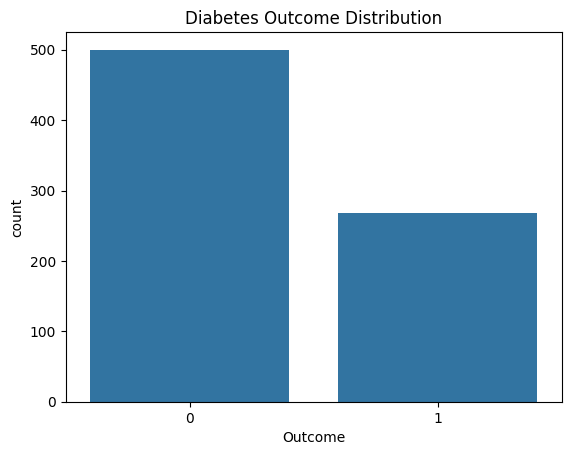

In [ ]:
# --Univariate Ananlysis---
sns.countplot(x='Outcome',data=df_eda)
plt.title("Diabetes Outcome Distribution")
plt.show()

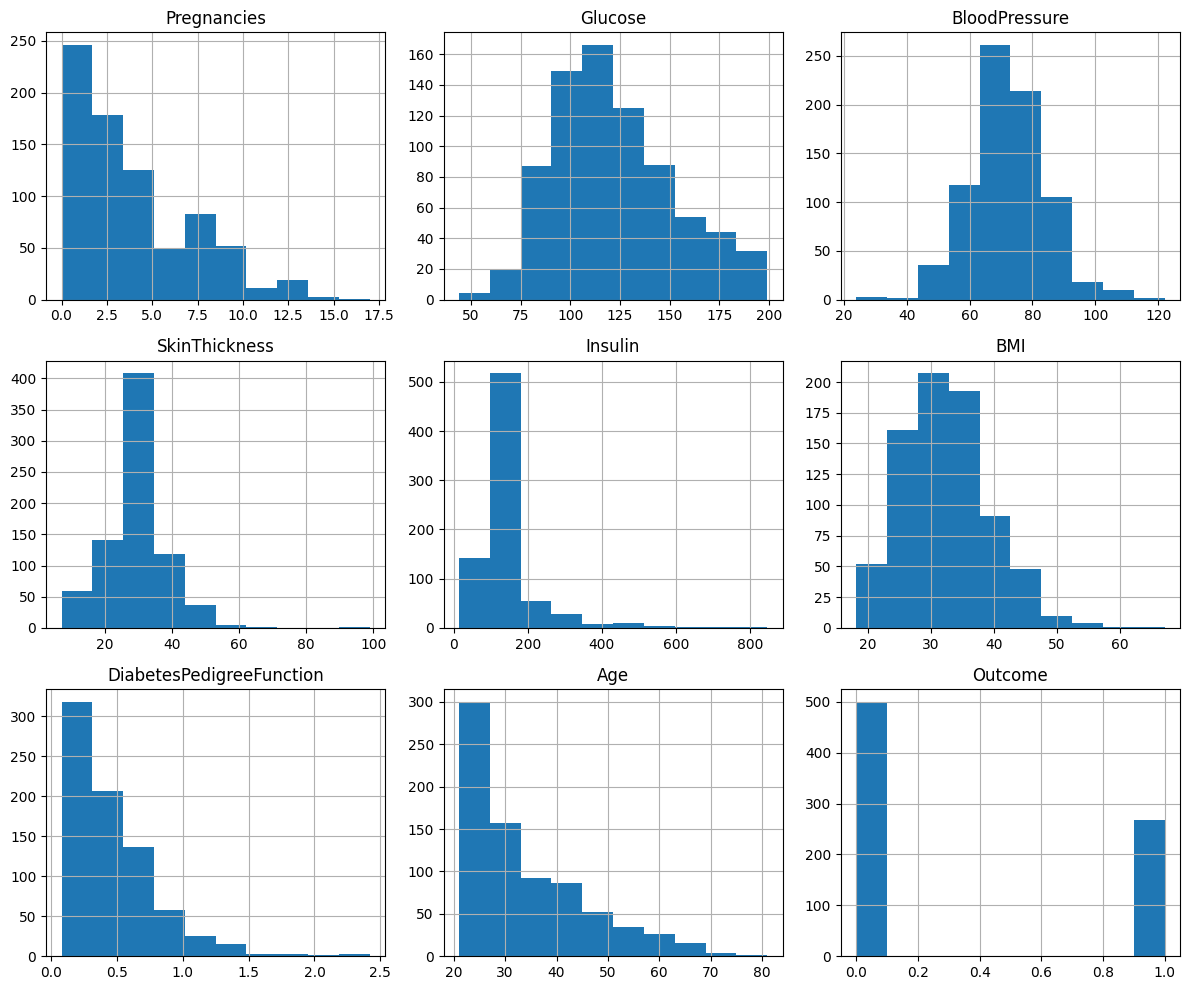

In [ ]:
df_eda.hist(figsize=(12,10))
plt.tight_layout()
plt.show()

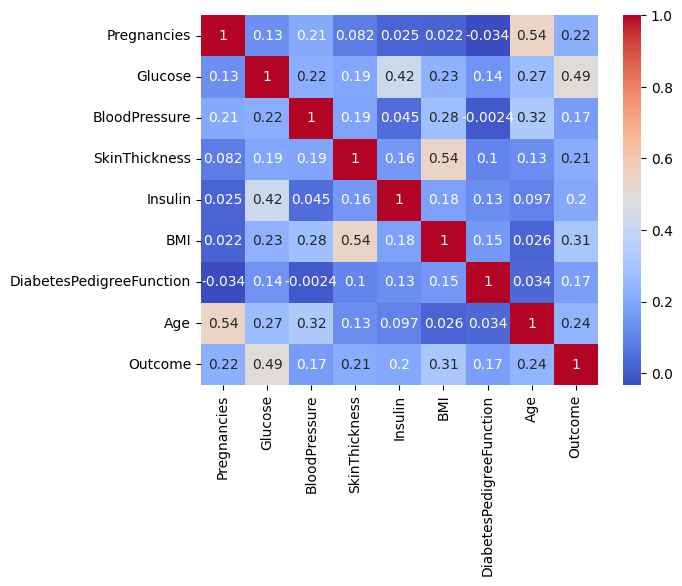

In [ ]:
#----Multivariate Analysis----
sns.heatmap(df_eda.corr(),annot=True,cmap='coolwarm')
plt.show()

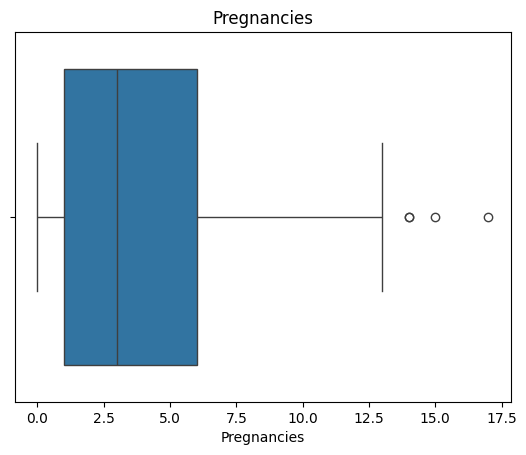

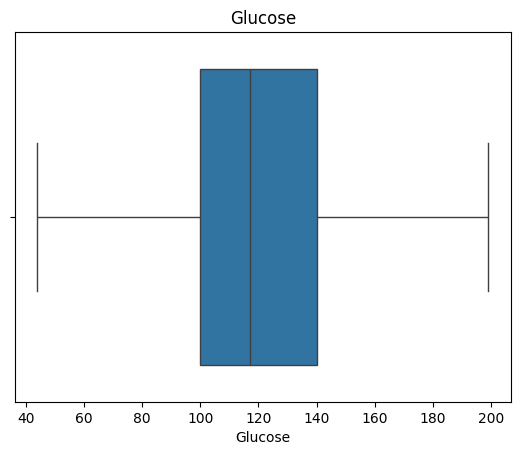

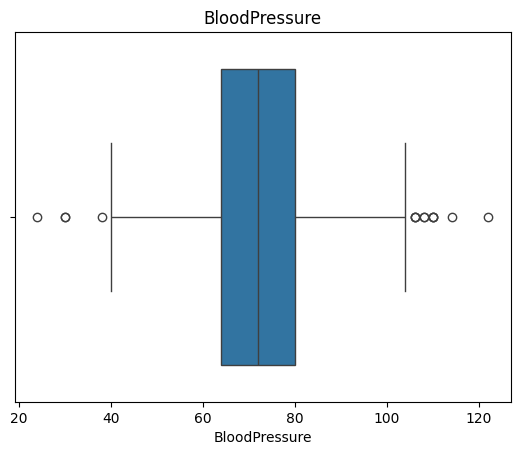

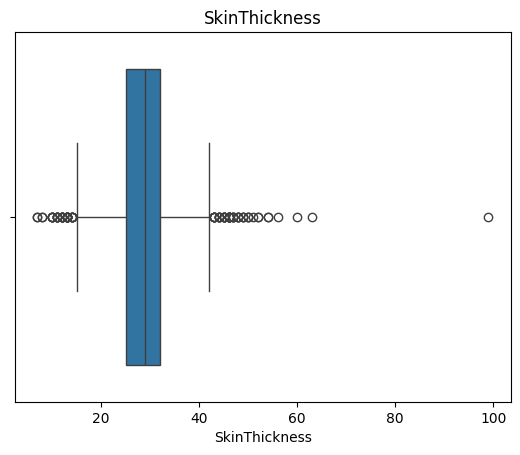

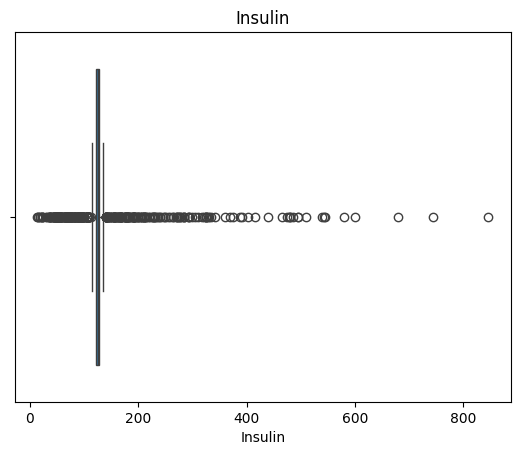

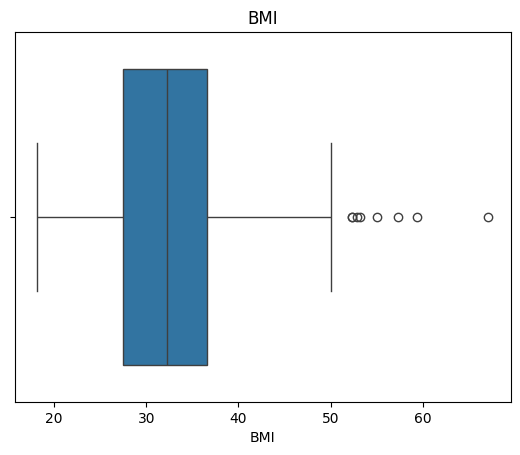

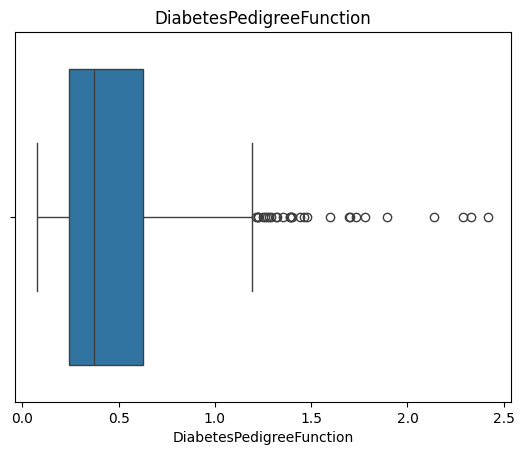

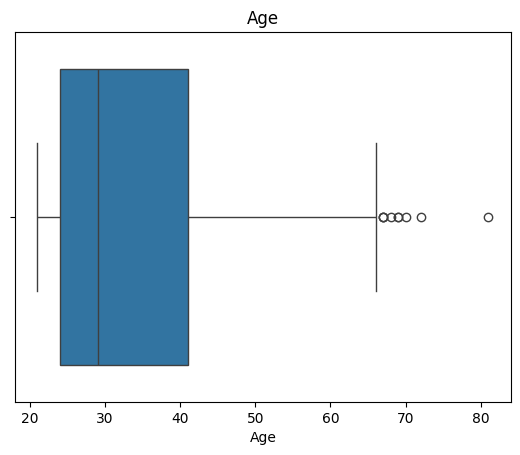

In [ ]:
for col in df_eda.drop(columns='Outcome').columns:
    sns.boxplot(x=df_eda[col])
    plt.title(col)
    plt.show()

In [ ]:
#------Outlier detection and treatment--------

In [ ]:
for col in df_eda.drop(columns='Outcome').columns:
    Q1 = df_eda[col].quantile(0.25)
    Q3 = df_eda[col].quantile(0.75)
    IQR = Q3-Q1

    lower_bound = Q1-1.5*IQR
    upper_bound = Q3+1.5*IQR

    df[col] = df[col].clip(lower_bound,upper_bound)

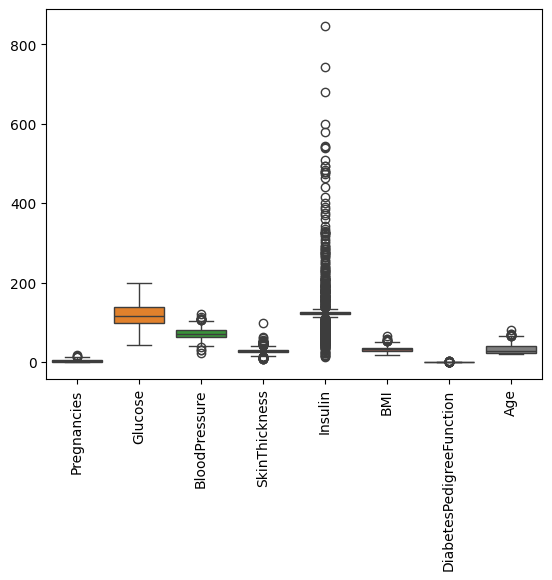

In [ ]:
sns.boxplot(data=df_eda.drop(columns='Outcome'))
plt.xticks(rotation=90)
plt.show()

In [ ]:
#-----Logistic Regression----

In [ ]:
x = df.drop(columns=['Outcome'])
y = df['Outcome']

In [ ]:
# Train_Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(
    x,y,test_size=0.20,random_state=42,stratify=y
)

In [ ]:
# Median Imputation
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [ ]:
# Scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Model Training
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)

model.fit(X_train,Y_train)

LogisticRegression(max_iter=1000)

In [ ]:
# Prediction
y_prob = model.predict_proba(X_test)[:,1]

y_pred = (y_prob >= 0.35).astype(int)

In [ ]:
# Evaluation Matrix
from sklearn.metrics import accuracy_score

print("Accuracy:",accuracy_score(Y_test,y_pred))

Accuracy: 0.7207792207792207


In [ ]:
# Classification_Report
from sklearn.metrics import classification_report

print(classification_report(Y_test,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.73      0.77       100
           1       0.58      0.70      0.64        54

    accuracy                           0.72       154
   macro avg       0.70      0.72      0.71       154
weighted avg       0.74      0.72      0.73       154



In [ ]:
# Confsuion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test,y_pred)
cm

array([[73, 27],
       [16, 38]])

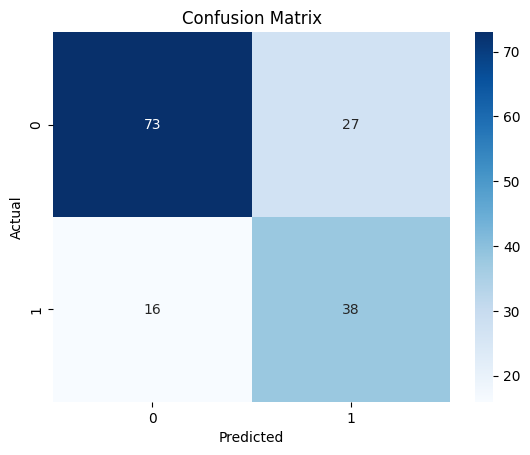

In [ ]:
# Visulisation - Confusion Matrix
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Roc_Auc Curve
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:,1]

roc_auc_score(Y_test,y_prob)

np.float64(0.8074074074074075)

In [ ]:
# Training and Testing
print("Training Accuracy:",model.score(X_train,Y_train))
print("Testing Accuracy:",model.score(X_test,Y_test))

Training Accuracy: 0.7882736156351792
Testing Accuracy: 0.7077922077922078


In [ ]:
#-----: Coefficient interpretation--------------

In [ ]:
# Features and Coefficients
coef = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': model.coef_[0]
})

coef

,Feature,Coefficient
0,Pregnancies,0.365583
1,Glucose,1.089335
2,BloodPressure,-0.029116
3,SkinThickness,0.017918
4,Insulin,0.192313
5,BMI,0.659181
6,DiabetesPedigreeFunction,0.268599
7,Age,0.158324


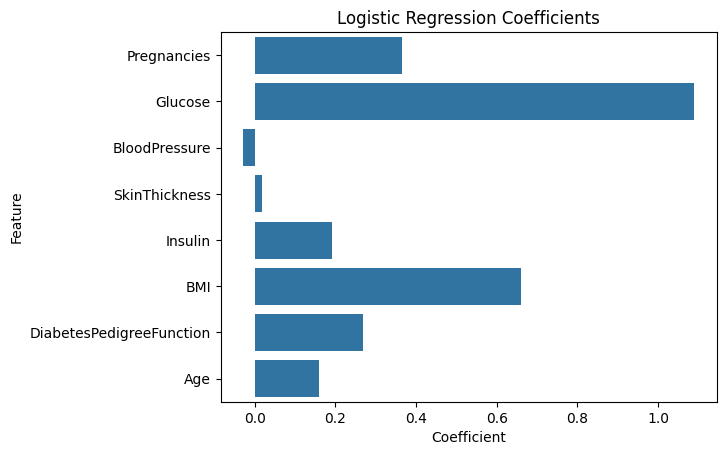

In [ ]:
#Visualisation
sns.barplot(data=coef,x='Coefficient',y='Feature')
plt.title("Logistic Regression Coefficients")
plt.show()